In [38]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import seaborn as sns

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.ExperimentSet import ExperimentSet

In [ ]:
EXPERIMENT_SET = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08'
V08 = ExperimentSet(EXPERIMENT_SET)
V08.set_retrieval_list()
V08.load_retrievals(iteration=-1)

In [14]:
Rlist = [R for R in V08.retrievals]
for i, R in enumerate(V08.retrievals):
    print('{}: {}'.format(i, R))

0: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/LCL_CTH
1: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained
2: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained_darksurf
3: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/HBC/periodic
4: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p150
5: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p250
6: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix22
7: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix54
8: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast
9: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast_unconstrained
10: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/slow
11: /data/gdi/b/johntl3/LundstromPub2025/exper

In [16]:
V08.retrievals[Rlist[0]].get_extinction(0.67,'cloud')

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       ...,

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan

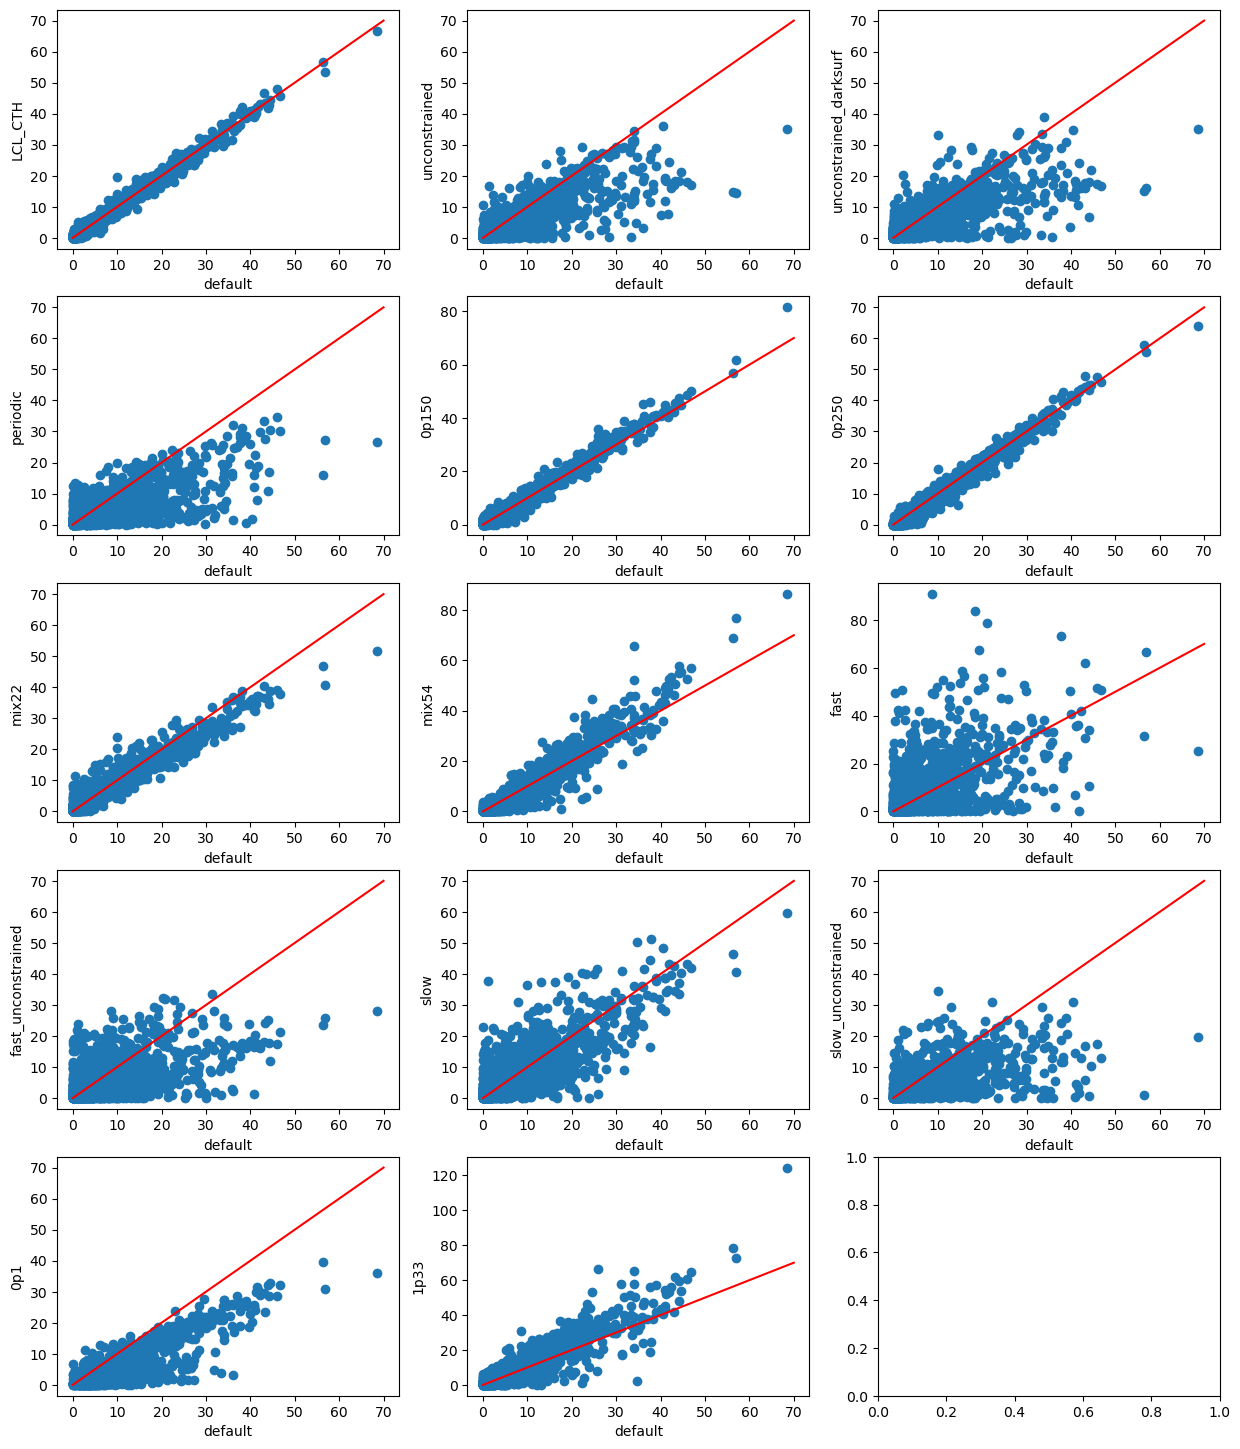

In [29]:
plot_i = [[12,0],[12,1],[12,2],[12,3],[12,4],[12,5],[12,6],[12,7],[12,8],[12,9],[12,10],[12,11],[12,13],[12,14]]

f, ax = plt.subplots(5, 3, figsize=(15,18))
for i, group in enumerate(plot_i):
    ax_tmp = ax.flatten()[i]
    R1 = V08.retrievals[Rlist[group[0]]]
    R2 = V08.retrievals[Rlist[group[1]]]
    ax_tmp.scatter(
        R1.get_extinction(0.67,'cloud'),
        R2.get_extinction(0.67,'cloud')
    )
    ax_tmp.set_xlabel(R1.exp_name)
    ax_tmp.set_ylabel(R2.exp_name)
    ax_tmp.plot([0,70],[0,70],'r')

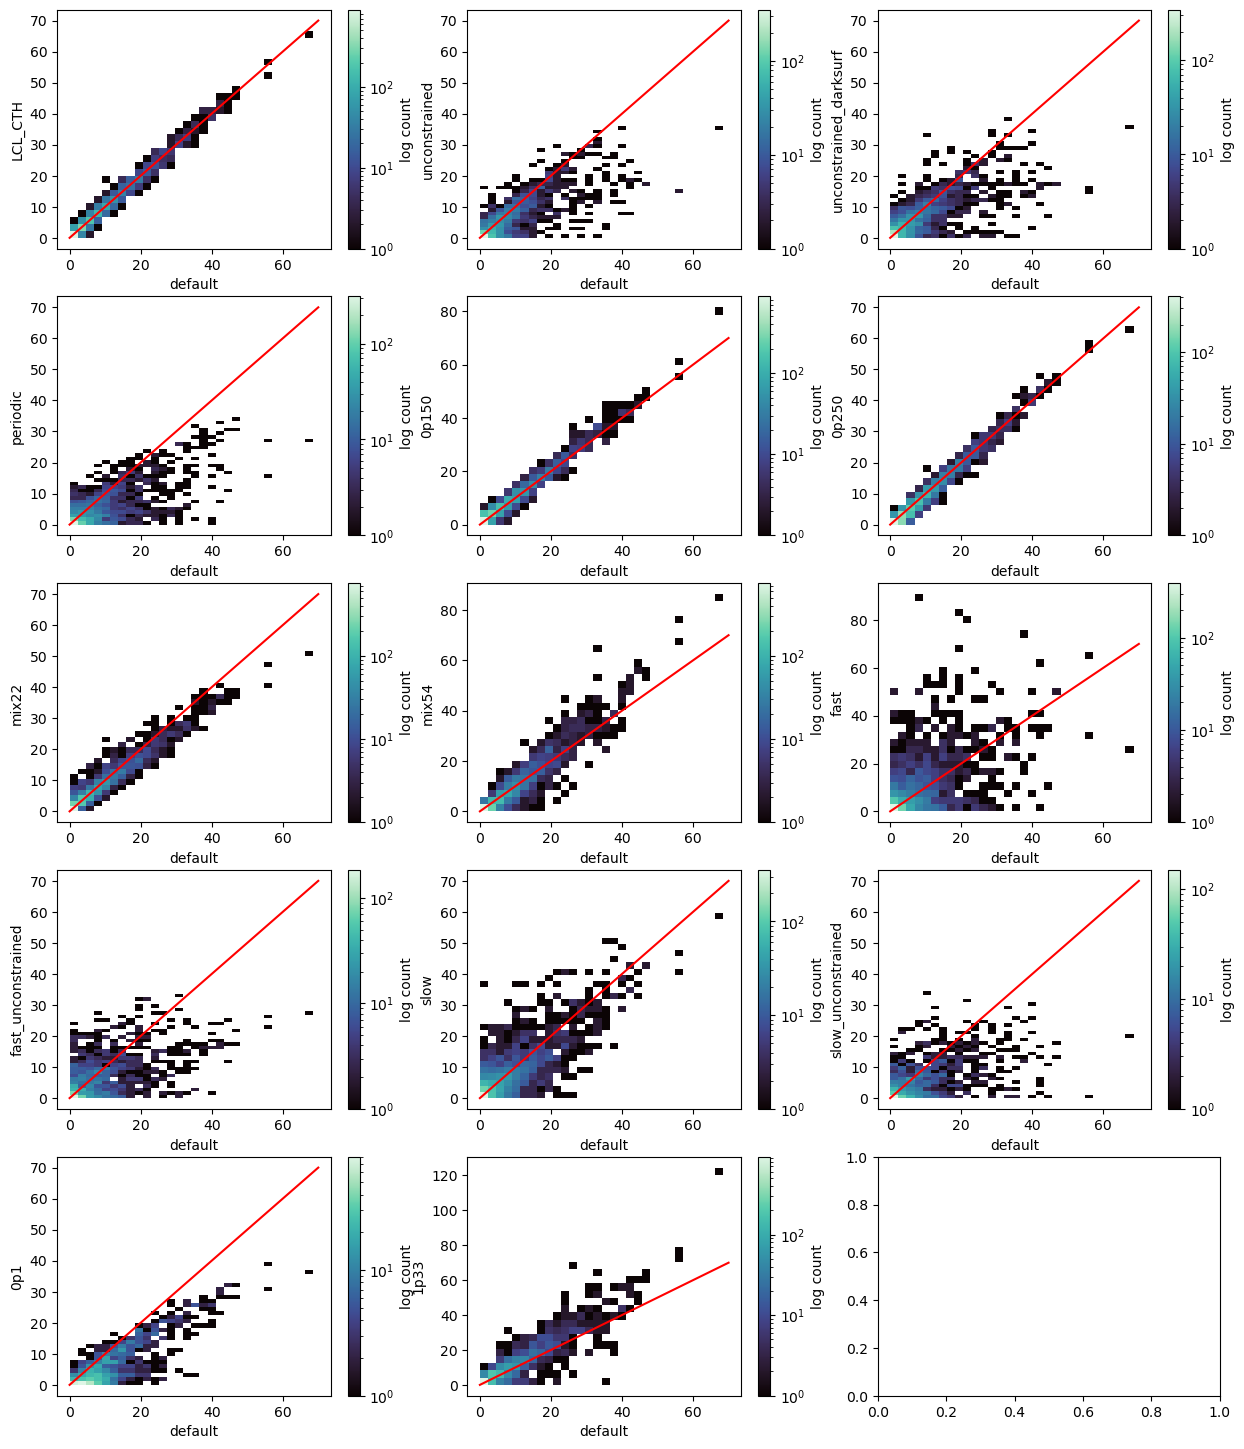

In [40]:
plot_i = [[12,0],[12,1],[12,2],[12,3],[12,4],[12,5],[12,6],[12,7],[12,8],[12,9],[12,10],[12,11],[12,13],[12,14]]

f, ax = plt.subplots(5, 3, figsize=(15,18))
for i, group in enumerate(plot_i):
    ax_tmp = ax.flatten()[i]
    R1 = V08.retrievals[Rlist[group[0]]]
    R2 = V08.retrievals[Rlist[group[1]]]
    hist = sns.histplot(
        x=np.ravel(R1.get_extinction(0.67,'cloud')),
        y=np.ravel(R2.get_extinction(0.67,'cloud')),
        ax=ax_tmp,
        bins=30,
        cmap='mako',
        cbar=False,
    )
    mesh = hist.collections[0]
    mesh.set_norm(LogNorm(vmin=1, vmax=max(1, mesh.get_array().max())))
    cbar = f.colorbar(mesh, ax=ax_tmp)
    cbar.set_label('log count')
    ax_tmp.set_xlabel(R1.exp_name)
    ax_tmp.set_ylabel(R2.exp_name)
    ax_tmp.plot([0,70],[0,70],'r')